# Final de Bioinformática · Análisis de datos (DM y ML)
**Bioingeniería · Lisandro Requelme**

**Profesores** Ignacio García Labari

Dataset GSE135251 · Fibrosis hepática



https://www.ncbi.nlm.nih.gov/geo/query/acc.cgi?acc=GSE135251

Para este trabajo elegí el dataset **GSE135251**, con conteos de expresión génica de biopsias hepáticas. Se seleccionaron 153 casos de la cohorte de NAFLD, 85 con estadio F0–F1 y 68 con F3–F4.

## Origen de los datos y objetivos

La serie proviene del estudio *Transcriptomic profiling across the nonalcoholic fatty liver disease spectrum reveals gene signatures for steatohepatitis and fibrosis* de Govaere y colaboradores, publicado en 2020 en *Science Translational Medicine* (DOI [10.1126/scitranslmed.aba4448](https://doi.org/10.1126/scitranslmed.aba4448)). El estudio multicéntrico, con participación de Newcastle University y centros de otros países europeos, analizó la expresión génica mediante RNA-seq de biopsias hepáticas.

- Comparar la expresión génica de F3–F4 frente a F0–F1 en Galaxy.
- Explorar los perfiles en Colab con PCA, K-Means y agrupamiento jerárquico.
- Evaluar y comparar un árbol de decisión, Random Forest, SVM con kernel RBF y polinómico y una red neuronal usando biopsias reservadas para prueba.

La respuesta **FIBROSIS** vale 0 para F0–F1 y 1 para F3–F4. La clasificación se obtiene del estadio informado en los metadatos. Los conteos se transforman a log2(1 + CPM) para preparar los perfiles de expresión.


In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import confusion_matrix, accuracy_score, recall_score, precision_score, f1_score, balanced_accuracy_score
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.model_selection import train_test_split

In [ ]:
# Importación y preparación de datos
from pathlib import Path
from zipfile import ZipFile, is_zipfile

archivo_zip = Path("GSE135251_Fibrosis_Galaxy.zip")
assert archivo_zip.is_file(), "Subí GSE135251_Fibrosis_Galaxy.zip al panel Archivos."
assert is_zipfile(archivo_zip), "El archivo subido debe ser un ZIP válido y completo."

with ZipFile(archivo_zip) as archivo:
    rutas = [
        nombre for nombre in archivo.namelist()
        if Path(nombre).name == "muestras.tsv"
    ]
    assert len(rutas) == 1, "El ZIP debe contener un único muestras.tsv."
    carpeta = rutas[0].removesuffix("muestras.tsv")

    with archivo.open(rutas[0]) as entrada:
        muestras = pd.read_csv(entrada, sep="	").set_index(
            "muestra", verify_integrity=True
        )

    assert len(muestras) == 153, "Se esperan las 153 biopsias del proyecto."
    assert muestras["grupo"].isin(["F0_F1", "F3_F4"]).all()
    tablas = []
    for muestra, fila in muestras.iterrows():
        with archivo.open(f"{carpeta}{fila.grupo}/{muestra}.tsv") as entrada:
            conteos = pd.read_csv(
                entrada, sep="	", header=None,
                names=["gen", muestra], index_col=0
            )
        assert conteos.index.is_unique, f"Genes repetidos en {muestra}."
        tablas.append(conteos[muestra])

conteos = pd.concat(tablas, axis=1).T
assert conteos.index.equals(muestras.index)
assert not conteos.isna().any().any(), "Falta correspondencia entre genes."
assert (conteos >= 0).all().all()
assert (conteos.sum(axis=1) > 0).all()

# Transformación por muestra para preparar la expresión génica
df = np.log2(1 + conteos.div(conteos.sum(axis=1), axis=0) * 1_000_000)
df["FIBROSIS"] = muestras["grupo"].map({"F0_F1": 0, "F3_F4": 1})


In [ ]:
df.shape

(153, 64254)

**¿Cuántas columnas hay? Describir cada una de ellas.**

La tabla contiene **64.254 columnas**, 64.253 genes y la respuesta FIBROSIS.


In [ ]:
display(df)


gen,ENSG00000000003,ENSG00000000005,ENSG00000000419,ENSG00000000457,ENSG00000000460,ENSG00000000938,ENSG00000000971,ENSG00000001036,ENSG00000001084,ENSG00000001167,...,ENSG00000280446,ENSG00000280447,ENSG00000280448,ENSG00000280449,ENSG00000280450,ENSG00000280451,ENSG00000280452,ENSG00000280453,ENSG00000280454,FIBROSIS
GSM3998168,6.922819,0.767179,4.772027,4.133044,2.449514,2.475759,10.922589,5.546161,6.813882,4.043762,...,0.0,0.0,0.070580,0.0,0.0,0.0,0.070580,0.000000,0.0,1
GSM3998170,6.673578,0.000000,4.639487,3.991293,2.156565,2.350584,10.576376,5.402187,6.437010,3.951948,...,0.0,0.0,0.000000,0.0,0.0,0.0,0.000000,0.000000,0.0,1
GSM3998171,6.781406,0.000000,4.980300,3.726883,2.262664,2.600513,10.627044,5.002633,6.840606,3.916924,...,0.0,0.0,0.000000,0.0,0.0,0.0,0.000000,0.049873,0.0,0
GSM3998172,6.488626,0.356995,4.396020,3.898929,1.850805,2.843304,11.292521,5.369765,6.730137,4.067158,...,0.0,0.0,0.000000,0.0,0.0,0.0,0.000000,0.000000,0.0,0
GSM3998173,6.886538,0.057137,4.821169,3.869329,2.356344,2.662817,10.782831,4.932238,7.001987,4.252355,...,0.0,0.0,0.000000,0.0,0.0,0.0,0.000000,0.000000,0.0,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
GSM3998377,6.952261,0.058255,4.925029,4.161426,2.222586,3.246156,10.929611,5.421723,7.021157,3.966059,...,0.0,0.0,0.000000,0.0,0.0,0.0,0.000000,0.000000,0.0,0
GSM3998378,6.798540,0.068491,4.232258,3.717527,2.772803,3.505378,10.814071,5.789417,6.443076,3.805439,...,0.0,0.0,0.000000,0.0,0.0,0.0,0.000000,0.000000,0.0,1
GSM3998379,6.624140,0.207418,4.612566,4.097540,2.514985,3.163973,10.627245,5.895394,6.675237,3.814080,...,0.0,0.0,0.000000,0.0,0.0,0.0,0.000000,0.000000,0.0,1
GSM3998380,6.587807,0.604961,4.811920,3.970942,2.315585,3.043653,10.902964,5.229317,7.047926,4.162434,...,0.0,0.0,0.000000,0.0,0.0,0.0,0.000000,0.191656,0.0,0


**¿Cuántos datos tiene el conjunto de datos?**

153 biopsias y 64.254 columnas, incluida la respuesta.

**¿Cúal es la variable objetivo, y cuáles y cuántas son las clases que toma la misma?**

In [ ]:
y_fibrosis = df["FIBROSIS"]
print(y_fibrosis.value_counts().sort_index().rename(
    index={0: "F0–F1", 1: "F3–F4"}
))

FIBROSIS
F0–F1    85
F3–F4    68
Name: count, dtype: int64


La variable objetivo es **FIBROSIS**, con dos clases. El valor 0 corresponde a F0–F1 y el 1 a F3–F4. Se asigna a cada biopsia según sus metadatos.


**¿Cuántos features numéricos y categóricos tiene?**

In [ ]:
numericas = df.columns.drop('FIBROSIS')

In [ ]:
print('Features numéricos:', len(numericas))
print('Features categóricos:', len(df.columns.drop('FIBROSIS')) - len(numericas))


Features numéricos: 64253
Features categóricos: 0


Los 64.253 predictores son numéricos. La respuesta FIBROSIS es categórica y utiliza los códigos 0 y 1.

**¿De las features numéricas, cuales son sus mínimos y máximos?**

In [ ]:
df[numericas].describe()

gen,ENSG00000000003,ENSG00000000005,ENSG00000000419,ENSG00000000457,ENSG00000000460,ENSG00000000938,ENSG00000000971,ENSG00000001036,ENSG00000001084,ENSG00000001167,...,ENSG00000280445,ENSG00000280446,ENSG00000280447,ENSG00000280448,ENSG00000280449,ENSG00000280450,ENSG00000280451,ENSG00000280452,ENSG00000280453,ENSG00000280454
count,153.000000,153.000000,153.000000,153.000000,153.000000,153.000000,153.000000,153.000000,153.000000,153.000000,...,153.000000,153.000000,153.000000,153.000000,153.0,153.0,153.0,153.000000,153.000000,153.0
mean,6.520086,0.154019,4.380779,3.848858,2.168016,2.556110,10.942187,5.260187,6.635346,3.824231,...,0.001154,0.000989,0.000321,0.011481,0.0,0.0,0.0,0.011889,0.028885,0.0
std,0.349030,0.280677,0.423534,0.242604,0.451826,0.492281,0.437058,0.269801,0.407844,0.268727,...,0.011015,0.009019,0.003975,0.030570,0.0,0.0,0.0,0.036907,0.058217,0.0
min,5.258478,0.000000,2.417522,3.038309,0.981491,1.514825,9.497442,4.600636,4.909846,2.937276,...,0.000000,0.000000,0.000000,0.000000,0.0,0.0,0.0,0.000000,0.000000,0.0
25%,6.352365,0.000000,4.150454,3.738066,1.866094,2.195036,10.608469,5.055572,6.429750,3.681076,...,0.000000,0.000000,0.000000,0.000000,0.0,0.0,0.0,0.000000,0.000000,0.0
50%,6.557656,0.052949,4.418729,3.876896,2.166570,2.524696,10.947933,5.239327,6.719911,3.826401,...,0.000000,0.000000,0.000000,0.000000,0.0,0.0,0.0,0.000000,0.000000,0.0
75%,6.778845,0.180129,4.618625,3.987169,2.449514,2.863248,11.289754,5.434531,6.908674,4.028345,...,0.000000,0.000000,0.000000,0.000000,0.0,0.0,0.0,0.000000,0.048493,0.0
max,7.082282,1.904253,5.415738,4.383624,3.332538,4.431742,11.807222,5.895394,7.365909,4.545170,...,0.127407,0.098804,0.049164,0.145538,0.0,0.0,0.0,0.247389,0.256891,0.0


In [ ]:
#Podemos recortar la tabla con el sgte codigo para observar de mejor manera el max y min
df[numericas].describe().loc[['min', 'max']] #selecciona filas por su nombre

gen,ENSG00000000003,ENSG00000000005,ENSG00000000419,ENSG00000000457,ENSG00000000460,ENSG00000000938,ENSG00000000971,ENSG00000001036,ENSG00000001084,ENSG00000001167,...,ENSG00000280445,ENSG00000280446,ENSG00000280447,ENSG00000280448,ENSG00000280449,ENSG00000280450,ENSG00000280451,ENSG00000280452,ENSG00000280453,ENSG00000280454
min,5.258478,0.000000,2.417522,3.038309,0.981491,1.514825,9.497442,4.600636,4.909846,2.937276,...,0.000000,0.000000,0.000000,0.000000,0.0,0.0,0.0,0.000000,0.000000,0.0
max,7.082282,1.904253,5.415738,4.383624,3.332538,4.431742,11.807222,5.895394,7.365909,4.545170,...,0.127407,0.098804,0.049164,0.145538,0.0,0.0,0.0,0.247389,0.256891,0.0


La tabla muestra los valores mínimos y máximos observados para cada característica numérica.

**¿De las features categóricas, cuantos valores únicos tienen?**


In [ ]:
categoricas = df.columns.drop('FIBROSIS').drop(numericas)
print(df[categoricas].nunique().rename('Valores únicos sin contar faltantes').to_string())


Series([], )


La lista de predictores categóricos está vacía porque todos los predictores son niveles de expresión génica.

**¿Hay valores faltantes?¿Cuántos?**

In [ ]:
df.isna().sum().sum()

np.int64(0)

La carga verifica la correspondencia entre genes y la ausencia de valores faltantes. El resultado esperado es cero.

**Si deciden eliminar las filas con valores faltantes, ¿cuantas eliminarían?**

In [ ]:
df.isna().any(axis=1).sum()

np.int64(0)

La cantidad de biopsias con algún valor faltante se calcula en la celda anterior. La entrada del proyecto conserva las 153 biopsias.

In [ ]:
df['FIBROSIS'].unique()

array([1, 0])

La respuesta ya está codificada con los valores 0 y 1, según los estadios de fibrosis. Los predictores son valores de expresión génica.

In [ ]:
# Conservar los predictores y la respuesta
datos_limpios = df.drop(columns='FIBROSIS').copy()
datos_limpios['FIBROSIS'] = y_fibrosis
print(datos_limpios['FIBROSIS'].value_counts().sort_index())


FIBROSIS
0    85
1    68
Name: count, dtype: int64


Se conservan las 153 biopsias y todos los genes disponibles. La respuesta queda en la última columna para mantener la organización del modelo de referencia.

In [ ]:
print(datos_limpios.shape)

(153, 64254)


In [ ]:
# Porcentaje de valores faltantes por columna
porcentaje_faltantes = datos_limpios.isna().sum() / len(datos_limpios) * 100

print(porcentaje_faltantes.sort_values(ascending=False))

gen
ENSG00000000003    0.0
ENSG00000000005    0.0
ENSG00000000419    0.0
ENSG00000000457    0.0
ENSG00000000460    0.0
                  ... 
ENSG00000280451    0.0
ENSG00000280452    0.0
ENSG00000280453    0.0
ENSG00000280454    0.0
FIBROSIS           0.0
Length: 64254, dtype: float64


In [ ]:
print('Dimensiones:', datos_limpios.shape)
print('Predictores:', datos_limpios.shape[1] - 1)
print(datos_limpios['FIBROSIS'].value_counts().sort_index())

Dimensiones: (153, 64254)
Predictores: 64253
FIBROSIS
0    85
1    68
Name: count, dtype: int64


In [ ]:
# Conservar la tabla para la evaluación con test independiente
datos_sin_imputar = datos_limpios.copy()

print('Faltantes restantes:', datos_limpios.isna().sum().sum())
print('Dimensiones:', datos_limpios.shape)


Faltantes restantes: 0
Dimensiones: (153, 64254)


In [ ]:
datos_limpios.to_csv('datos_limpios.txt', index=False)

**¿Las clases están balanceadas? ¿Cuántos datos tiene cada una de ellas?**

In [ ]:
print(datos_limpios['FIBROSIS'].value_counts().sort_index())
print((datos_limpios['FIBROSIS'].value_counts(normalize=True).sort_index()*100).round(2))

FIBROSIS
0    85
1    68
Name: count, dtype: int64
FIBROSIS
0    55.56
1    44.44
Name: proportion, dtype: float64


Las clases tienen 85 biopsias F0–F1 (55,56 %) y 68 F3–F4 (44,44 %).

**¿Cuántas dimensiones habría en el caso que uno quisiera utilizar directamente a todos los
features para graficar?**

In [ ]:
x = datos_limpios.drop(columns='FIBROSIS').to_numpy()
y = datos_limpios['FIBROSIS'].to_numpy()

In [ ]:
x.shape

(153, 64253)

In [ ]:
y.shape

(153,)

Se utilizan 64.253 dimensiones de entrada, una por gen. La respuesta FIBROSIS se conserva en y.

**¿Las features están todas medidas con las mismas unidades?**

Los predictores representan expresión génica transformada a log2(1 + CPM). Aunque usan la misma transformación, cada gen puede tener un rango diferente de valores.


In [ ]:
from sklearn.preprocessing import MinMaxScaler

# Crear un objeto MinMaxScaler
scaler = MinMaxScaler()

# Normalizar los datos
datos_normalizados = scaler.fit_transform(x)

# Convertirlo a un DataFrame para mejor visualización
datos_normalizados_df = pd.DataFrame(
    datos_normalizados,
    columns=datos_limpios.columns[:-1]
)

print(datos_normalizados_df)

gen  ENSG00000000003  ENSG00000000005  ENSG00000000419  ENSG00000000457  \
0           0.912566         0.402876         0.785302         0.813739   
1           0.775906         0.000000         0.741096         0.708373   
2           0.835029         0.000000         0.854768         0.511831   
3           0.674496         0.187472         0.659892         0.639716   
4           0.892673         0.030005         0.801693         0.617714   
..               ...              ...              ...              ...   
148         0.928709         0.030592         0.836333         0.834836   
149         0.844423         0.035968         0.605272         0.504877   
150         0.748799         0.108924         0.732117         0.787348   
151         0.728877         0.317689         0.798608         0.693245   
152         0.587506         0.000000         0.581654         0.735762   

gen  ENSG00000000460  ENSG00000000938  ENSG00000000971  ENSG00000001036  \
0           0.624412    

**¿Por qué es importante normalizar los datos antes de aplicar PCA?**

PCA busca las direcciones de mayor variación de los datos. MinMaxScaler lleva las características al rango de 0 a 1, como en el modelo de referencia, y modifica el peso de sus diferentes rangos de expresión.


In [ ]:
from sklearn.decomposition import PCA

# Aplicar PCA
pca = PCA()
X_pca = pca.fit_transform(datos_normalizados)

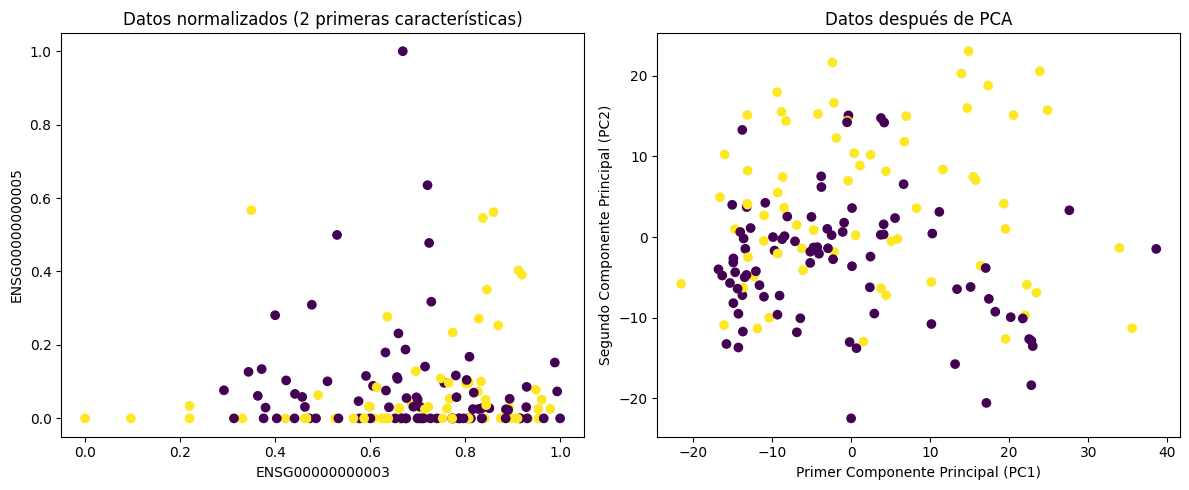

In [ ]:
import matplotlib.pyplot as plt

feature_names = datos_limpios.columns[:-1]

# Visualizar las dos primeras características normalizadas
plt.figure(figsize=(12, 5))
plt.subplot(121)
plt.scatter(datos_normalizados[:, 0], datos_normalizados[:, 1], c=y)
plt.title("Datos normalizados (2 primeras características)")
plt.xlabel(feature_names[0])
plt.ylabel(feature_names[1])

# Visualizar los datos después de aplicar PCA
plt.subplot(122)
plt.scatter(X_pca[:, 0], X_pca[:, 1], c=y)
plt.title("Datos después de PCA")
plt.xlabel("Primer Componente Principal (PC1)")
plt.ylabel("Segundo Componente Principal (PC2)")

plt.tight_layout()
plt.show()

La izquierda muestra los primeros dos genes normalizados. La derecha resume los perfiles mediante PC1 y PC2. El color indica la clase de fibrosis. PCA calcula las componentes a partir de los predictores.

In [ ]:
# Crear un DataFrame con los resultados del PCA
pca_df = pd.DataFrame(data={
    'standard_deviation': np.sqrt(pca.explained_variance_),
    'proportion_of_variance': pca.explained_variance_ratio_,
    'cumulative_proportion': np.cumsum(pca.explained_variance_ratio_)
})

# Asignar nombres a los componentes principales
pca_df.index = [f'PC{i}' for i in range(1, len(pca_df) + 1)]
pca_df.index.name = 'component'

print("Resumen de PCA:")
print(pca_df)

Resumen de PCA:
           standard_deviation  proportion_of_variance  cumulative_proportion
component                                                                   
PC1              1.321224e+01            1.555022e-01               0.155502
PC2              9.303947e+00            7.711125e-02               0.232613
PC3              7.821189e+00            5.449152e-02               0.287105
PC4              6.224499e+00            3.451375e-02               0.321619
PC5              5.400421e+00            2.597997e-02               0.347599
...                       ...                     ...                    ...
PC149            1.548487e+00            2.135987e-03               0.993860
PC150            1.542648e+00            2.119909e-03               0.995980
PC151            1.524902e+00            2.071415e-03               0.998052
PC152            1.478951e+00            1.948458e-03               1.000000
PC153            2.294710e-14            4.690714e-31       

La fracción de varianza explicada por PC1 y PC2 se obtiene sumando sus valores de proportion_of_variance en la tabla anterior. Esta versión usa todos los genes, por lo que los resultados se calculan nuevamente.

In [ ]:
# Obtener los vectores de carga (loadings)
loadings = pca.components_.T

# Crear un DataFrame con los loadings
loadings_df = pd.DataFrame(
    loadings,
    columns=[f'PC{i}' for i in range(1, len(loadings[0]) + 1)],
    index=datos_limpios.columns[:-1]
)

print("Vectores de carga (Loadings):")
print(loadings_df)

Vectores de carga (Loadings):
                      PC1       PC2       PC3       PC4       PC5       PC6  \
gen                                                                           
ENSG00000000003 -0.009343  0.007976 -0.005758  0.009194  0.005179 -0.002540   
ENSG00000000005 -0.001234 -0.000211  0.003995  0.002418  0.001760 -0.004092   
ENSG00000000419 -0.005940  0.008140 -0.004058  0.009533  0.002203  0.004290   
ENSG00000000457 -0.004397  0.012141  0.000170  0.003614 -0.005352  0.005697   
ENSG00000000460 -0.003418  0.009691 -0.001234 -0.000710 -0.000185  0.006047   
...                   ...       ...       ...       ...       ...       ...   
ENSG00000280450  0.000000  0.000000 -0.000000 -0.000000  0.000000 -0.000000   
ENSG00000280451  0.000000  0.000000 -0.000000 -0.000000  0.000000 -0.000000   
ENSG00000280452  0.001196  0.002906  0.002862  0.000164 -0.002289 -0.003325   
ENSG00000280453  0.004579  0.000135  0.000772  0.000663 -0.008675 -0.001732   
ENSG00000280454  0.000

In [ ]:
print(loadings_df[['PC1', 'PC2']].to_string())

                          PC1           PC2
gen                                        
ENSG00000000003 -9.343047e-03  7.976211e-03
ENSG00000000005 -1.233859e-03 -2.111480e-04
ENSG00000000419 -5.939502e-03  8.139964e-03
ENSG00000000457 -4.396539e-03  1.214140e-02
ENSG00000000460 -3.418070e-03  9.691382e-03
ENSG00000000938  4.750141e-03  6.944221e-03
ENSG00000000971 -1.152368e-02  7.982641e-04
ENSG00000001036  2.309854e-03  9.667824e-03
ENSG00000001084 -9.147964e-03  6.499104e-03
ENSG00000001167 -5.767459e-03  1.023537e-02
ENSG00000001460  2.836255e-03  7.770600e-03
ENSG00000001461 -3.297683e-03  5.481310e-03
ENSG00000001497  7.905065e-03  1.902589e-03
ENSG00000001561 -1.160740e-02  7.215712e-03
ENSG00000001617  9.197866e-03  1.986427e-03
ENSG00000001626  1.601014e-03  1.119918e-02
ENSG00000001629 -8.886632e-03  1.167221e-02
ENSG00000001630 -4.035447e-03 -5.855158e-03
ENSG00000001631 -8.514316e-03  1.040772e-02
ENSG00000002016  8.444888e-03  1.015819e-02
ENSG00000002079  2.485056e-03  4

La tabla muestra las cargas de cada gen. El mayor valor absoluto en una componente identifica el gen con mayor peso dentro de su vector. El signo indica la dirección.

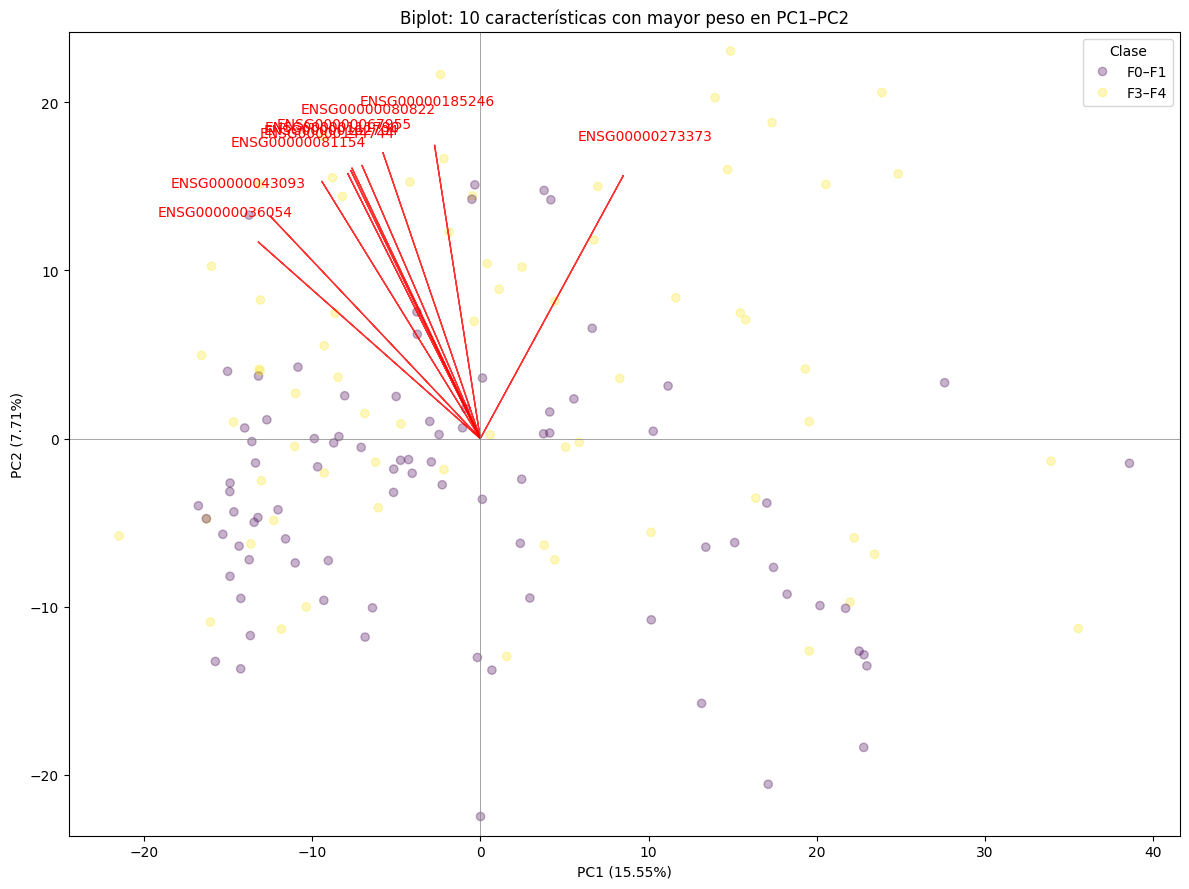

In [ ]:
features = datos_limpios.columns[:-1]

# Seleccionar las 10 características con mayor peso en el plano
importancia = np.sqrt(loadings[:, 0]**2 + loadings[:, 1]**2)
top = np.argsort(importancia)[::-1][:10]

plt.figure(figsize=(12, 9))

sc = plt.scatter(
    X_pca[:, 0], X_pca[:, 1],
    c=y, cmap='viridis', alpha=0.3
)

# Ampliar todas las flechas por el mismo factor para facilitar la lectura
escala = (
    0.4 * min(np.ptp(X_pca[:, 0]), np.ptp(X_pca[:, 1]))
    / importancia[top].max()
)

for i in top:
    lx = loadings[i, 0] * escala
    ly = loadings[i, 1] * escala

    plt.arrow(
        0, 0, lx, ly,
        color='r', alpha=0.8,
        head_width=0.03, length_includes_head=True
    )
    plt.text(
        lx * 1.15, ly * 1.15, features[i],
        color='r', ha='center', va='center', fontsize=10
    )

plt.axhline(0, color='grey', lw=0.5)
plt.axvline(0, color='grey', lw=0.5)
plt.legend(
    sc.legend_elements()[0],
    ['F0–F1', 'F3–F4'],
    title='Clase'
)
plt.xlabel(f'PC1 ({pca.explained_variance_ratio_[0]:.2%})')
plt.ylabel(f'PC2 ({pca.explained_variance_ratio_[1]:.2%})')
plt.title('Biplot: 10 características con mayor peso en PC1–PC2')
plt.axis('equal')
plt.tight_layout()
plt.show()

Se muestran las diez características con mayor peso conjunto en PC1 y PC2. Se conserva el factor de ampliación de flechas del modelo de referencia.

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.cluster import KMeans
from sklearn.preprocessing import MinMaxScaler
from sklearn.decomposition import PCA
from sklearn.metrics import accuracy_score

from scipy.spatial import ConvexHull
from scipy.optimize import linear_sum_assignment
from scipy.cluster.hierarchy import dendrogram, linkage, fcluster

# Cargar los predictores y las etiquetas de fibrosis
X_clustering = df.drop(columns="FIBROSIS").to_numpy()
y_true = df["FIBROSIS"].to_numpy()

# Crear un objeto MinMaxScaler
scaler_clustering = MinMaxScaler()

# Normalizar los datos
X_normalized = scaler_clustering.fit_transform(X_clustering)

# Aplicar PCA
pca_clustering = PCA()
X_pca_clustering = pca_clustering.fit_transform(X_normalized)

print("Dimensiones de entrada:", X_clustering.shape)
print("Dimensiones después de PCA:", X_pca_clustering.shape)

Dimensiones de entrada: (153, 64253)
Dimensiones después de PCA: (153, 153)


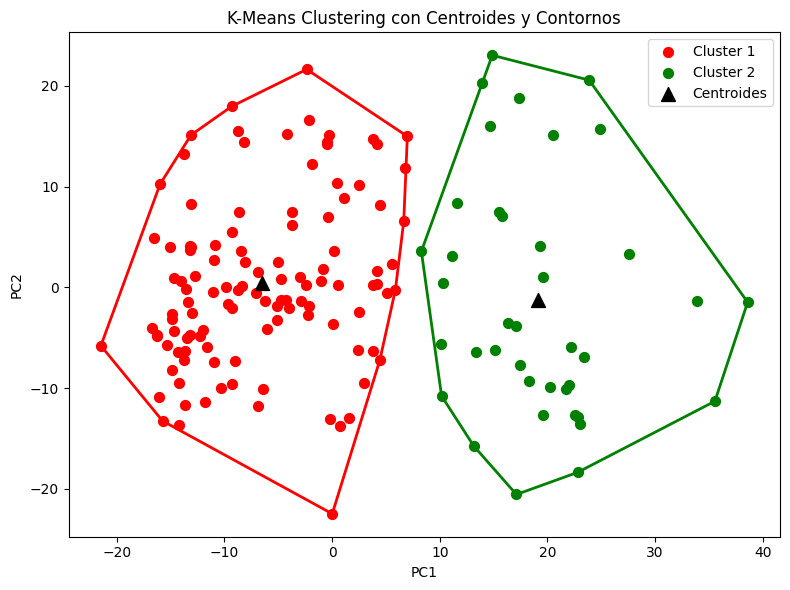

In [ ]:
# Aplicar K-Means
kmeans = KMeans(n_clusters=2, random_state=42)
kmeans_labels = kmeans.fit_predict(X_pca_clustering)

# Obtener los centroides
centroids = kmeans.cluster_centers_

# Visualización de K-Means con centroides y contornos
plt.figure(figsize=(8, 6))
colors = ["red", "green"]

for i in range(2):
    points = X_pca_clustering[kmeans_labels == i]

    plt.scatter(
        points[:, 0], points[:, 1],
        c=colors[i],
        label=f"Cluster {i + 1}",
        s=50
    )

    # Dibujar el contorno cuando hay suficientes puntos
    if len(points) >= 3 and np.linalg.matrix_rank(
        points[:, :2] - points[0, :2]
    ) == 2:
        hull = ConvexHull(points[:, :2])

        for simplex in hull.simplices:
            plt.plot(
                points[simplex, 0],
                points[simplex, 1],
                color=colors[i],
                lw=2
            )

# Dibujar los centroides con un triángulo negro
plt.scatter(
    centroids[:, 0], centroids[:, 1],
    marker="^", s=100, c="black",
    label="Centroides"
)

plt.title("K-Means Clustering con Centroides y Contornos")
plt.xlabel("PC1")
plt.ylabel("PC2")
plt.legend()
plt.tight_layout()
plt.show()

El gráfico muestra cómo K-Means agrupó las biopsias en dos clusters según la similitud de sus perfiles de expresión génica. Cada punto representa una biopsia y su color indica el grupo asignado: rojo para el cluster 1 y verde para el cluster 2. Los ejes PC1 y PC2 corresponden a las dos primeras componentes principales y permiten visualizar parte de la variación de los datos. Los triángulos negros representan los centroides, es decir, los centros de cada grupo, y los contornos unen sus puntos más externos en este plano. Se observa una separación principalmente a lo largo de PC1. Estos clusters no representan directamente los estadios F0–F1 y F3–F4, porque K-Means formó los grupos sin utilizar las etiquetas de fibrosis; su correspondencia con los estadios se evalúa posteriormente.

In [ ]:
# Clusters predichos por K-Means
y_pred_clustering = kmeans.labels_

# Crear la tabla de confusión inicial
cont_table = pd.crosstab(
    y_pred_clustering,
    y_true,
    rownames=["Cluster"],
    colnames=["Clase real"]
).reindex(index=[0, 1], columns=[0, 1], fill_value=0)

# Encontrar la mejor correspondencia entre clusters y clases
_, class_match = linear_sum_assignment(-cont_table.to_numpy())

# Ordenar las columnas según la correspondencia encontrada
optimized_cont_table = cont_table.iloc[:, class_match]

print("Tabla de correspondencia optimizada:")
print(optimized_cont_table)

# Convertir los clusters a las clases correspondientes
matched_labels = class_match[y_pred_clustering]

direct_agreement = accuracy_score(
    y_true, matched_labels
) * 100

print(f"\nDirect agreement: {direct_agreement:.2f}%")

Tabla de correspondencia optimizada:
Clase real   0   1
Cluster           
0           67  47
1           18  21

Direct agreement: 57.52%



Tabla de correspondencia optimizada (single):
Clase real   0   1
Cluster           
1           85  67
2            0   1
Direct agreement (single): 56.21%

Tabla de correspondencia optimizada (complete):
Clase real   1   0
Cluster           
1            2   1
2           66  84
Direct agreement (complete): 56.21%

Tabla de correspondencia optimizada (average):
Clase real   0   1
Cluster           
1           84  66
2            1   2
Direct agreement (average): 56.21%

Tabla de correspondencia optimizada (ward):
Clase real   1   0
Cluster           
1           14  16
2           54  69
Direct agreement (ward): 54.25%


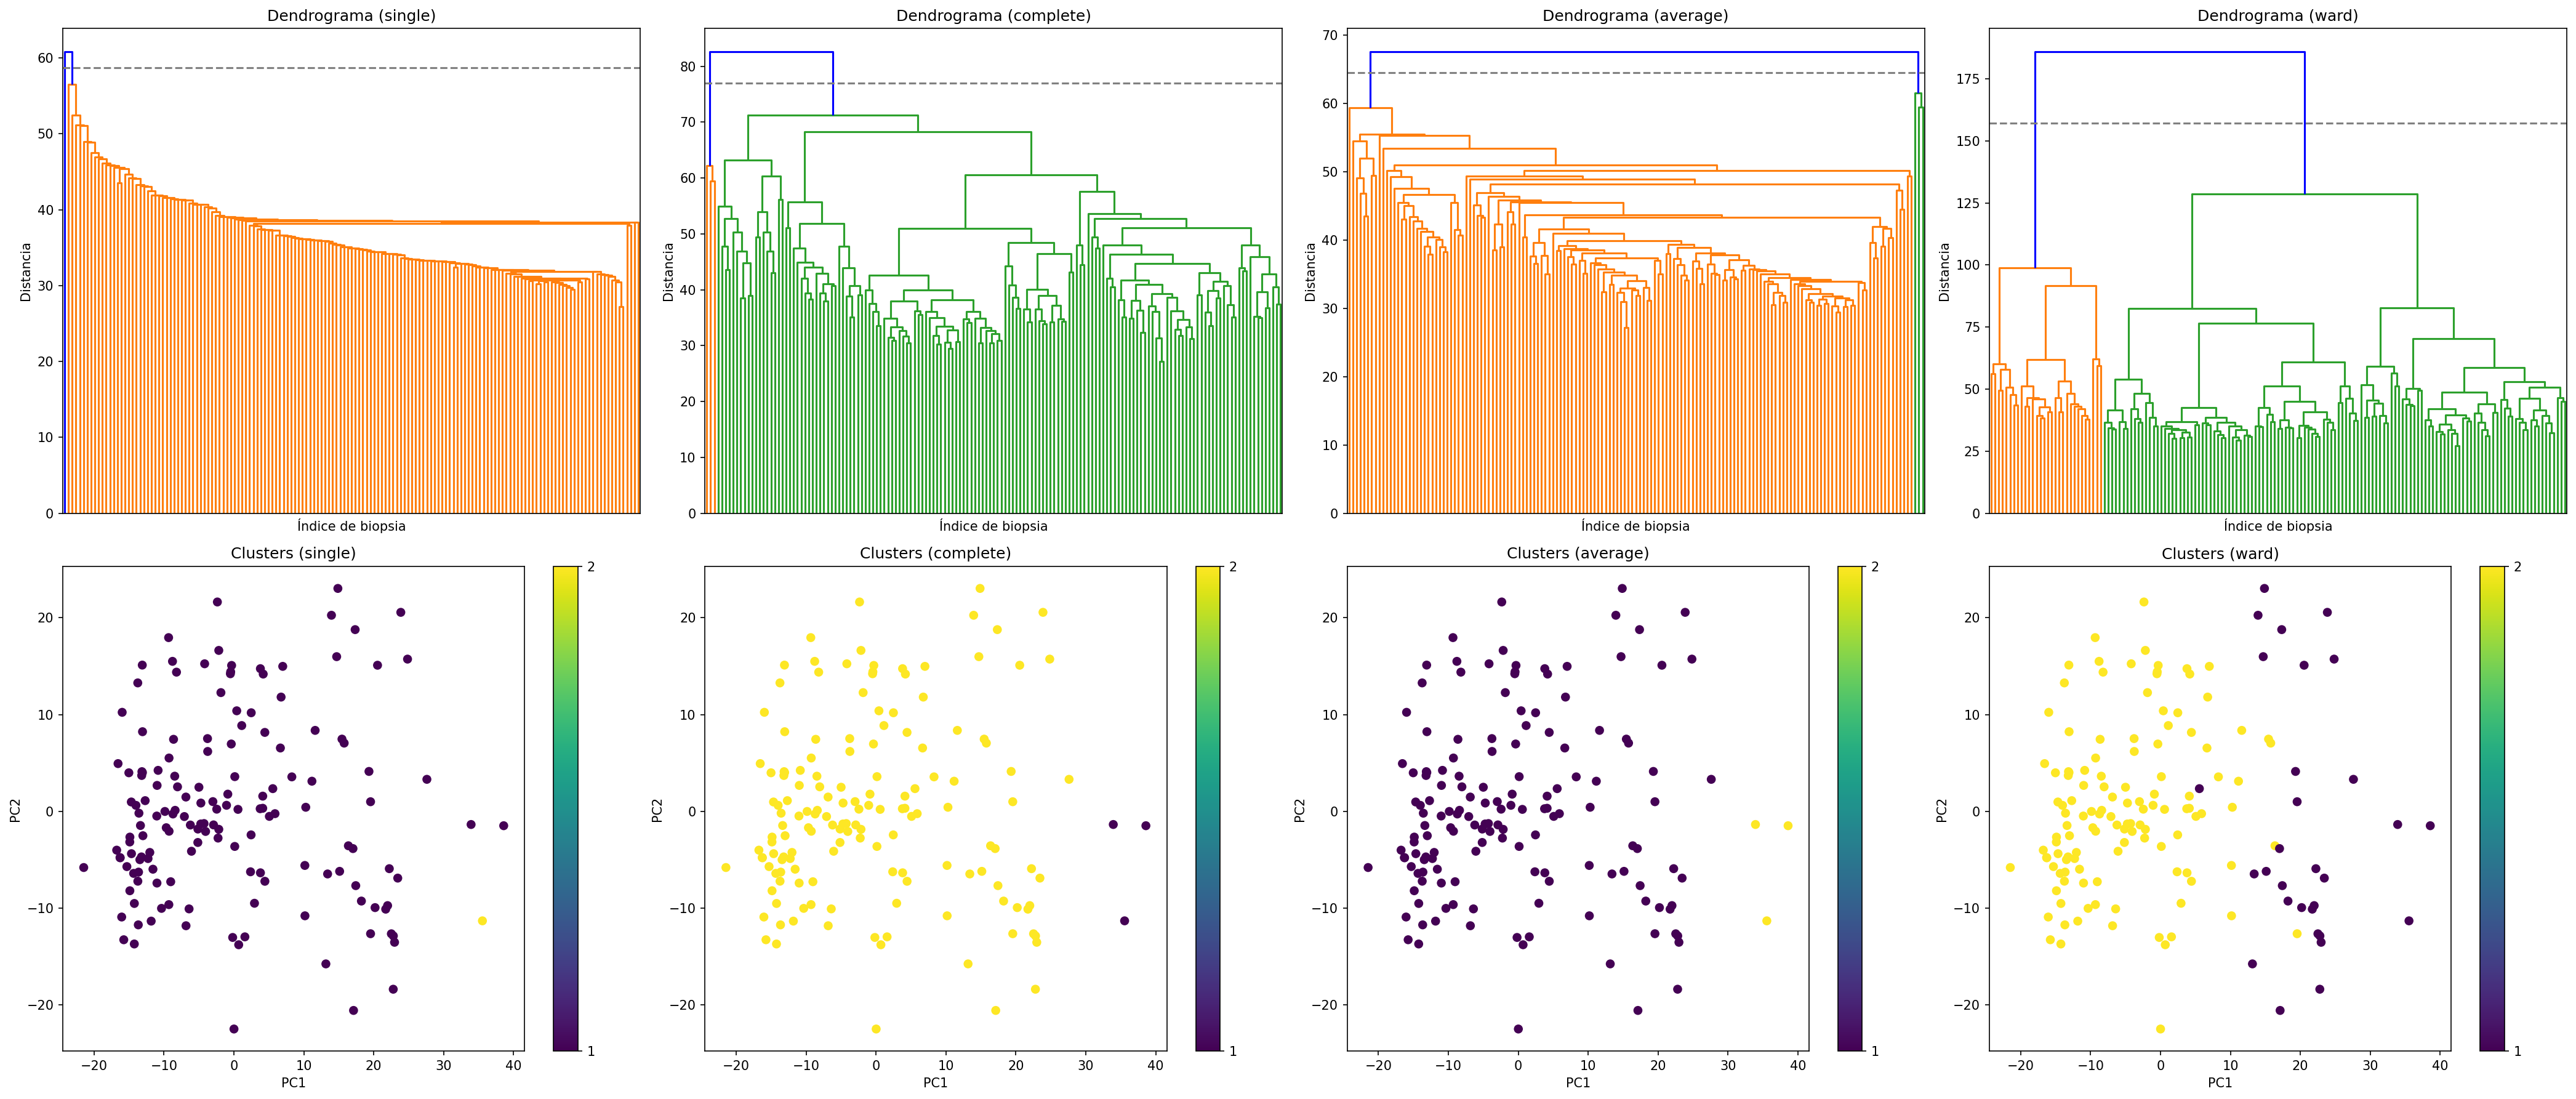

In [ ]:
# Estrategias de linkage
linkage_methods = ["single", "complete", "average", "ward"]

def plot_dendrogram_with_cut(Z, ax, n_clusters=2):
    # Situar el corte entre las dos últimas uniones
    color_threshold = (
        Z[-n_clusters, 2] + Z[-n_clusters + 1, 2]
    ) / 2

    # Dibujar el dendrograma
    dendrogram(
        Z,
        ax=ax,
        no_labels=True,
        color_threshold=color_threshold,
        above_threshold_color="blue"
    )

    # Agregar línea de corte
    ax.axhline(
        y=color_threshold,
        color="gray",
        linestyle="--"
    )

    ax.set_xlabel("Índice de biopsia")
    ax.set_ylabel("Distancia")


# Crear figura para los dendrogramas y scatter plots
fig, axs = plt.subplots(2, 4, figsize=(28, 12), dpi=150)

for i, method in enumerate(linkage_methods):
    # Aplicar clustering jerárquico
    Z = linkage(X_pca_clustering, method=method)

    y_pred_clustering = fcluster(
        Z, t=2, criterion="maxclust"
    )

    # Graficar el dendrograma con línea de corte
    axs[0, i].set_title(f"Dendrograma ({method})")

    plot_dendrogram_with_cut(
        Z, axs[0, i], n_clusters=2
    )

    # Graficar los primeros dos componentes principales
    scatter = axs[1, i].scatter(
        X_pca_clustering[:, 0],
        X_pca_clustering[:, 1],
        c=y_pred_clustering,
        cmap="viridis"
    )

    axs[1, i].set_title(f"Clusters ({method})")
    axs[1, i].set_xlabel("PC1")
    axs[1, i].set_ylabel("PC2")

    plt.colorbar(scatter, ax=axs[1, i], ticks=[1, 2])

    # Comparar clusters y clases reales
    cont_table = pd.crosstab(
        y_pred_clustering,
        y_true,
        rownames=["Cluster"],
        colnames=["Clase real"]
    ).reindex(index=[1, 2], columns=[0, 1], fill_value=0)

    _, class_match = linear_sum_assignment(
        -cont_table.to_numpy()
    )

    optimized_cont_table = cont_table.iloc[:, class_match]

    print(f"\nTabla de correspondencia optimizada ({method}):")
    print(optimized_cont_table)

    # Los clusters jerárquicos están numerados desde 1
    matched_labels = class_match[y_pred_clustering - 1]

    direct_agreement = accuracy_score(
        y_true, matched_labels
    ) * 100

    print(
        f"Direct agreement ({method}): "
        f"{direct_agreement:.2f}%"
    )

plt.tight_layout()
plt.show()

Primeros 4 graficos (dendogramas):

Los dendrogramas muestran cómo se agrupan las biopsias según la similitud de sus perfiles de expresión génica utilizando cuatro métodos de clustering jerárquico: single, complete, average y Ward. Cada extremo inferior representa una biopsia y las ramas indican cómo se van uniendo. La altura de cada unión refleja la distancia o diferencia entre los grupos según el método utilizado. La línea horizontal punteada señala el corte para obtener dos clusters, representados con colores diferentes.

Single une grupos según sus muestras más cercanas y presenta una estructura de encadenamiento, dejando una biopsia separada del resto. Complete considera las muestras más alejadas y average utiliza las distancias promedio; ambos generan un grupo muy grande y otro pequeño. Ward busca minimizar el aumento de la variación interna y produce dos grupos menos desiguales. Estos colores identifican los clusters obtenidos y no corresponden directamente a F0–F1 y F3–F4, porque los agrupamientos se construyen sin utilizar las etiquetas de fibrosis.

---

Clusters

Los gráficos muestran los dos clusters obtenidos con single, complete, average y Ward, representados sobre las dos primeras componentes principales, PC1 y PC2. Cada punto corresponde a una biopsia y su color indica el cluster asignado. La posición de las biopsias es la misma en los cuatro gráficos; lo que cambia es su agrupamiento según el método.

En single, casi todas las biopsias pertenecen a un mismo cluster y solo una queda separada. Complete y average también producen agrupamientos muy desiguales, separando tres biopsias del resto. Ward genera una división menos extrema, con diferencias visibles principalmente a lo largo de PC1. Los colores identifican clusters y no representan directamente los estadios F0–F1 y F3–F4; además, su numeración es arbitraria entre métodos. Aunque se visualizan únicamente PC1 y PC2, el agrupamiento se calculó utilizando todas las componentes disponibles, por lo que la separación completa no siempre resulta evidente en este plano.

In [ ]:
# Verificar las características y las etiquetas
print("Dimensiones de x:", x.shape)
print("Dimensiones de y:", y.shape)

# Contar las biopsias de cada clase
print("Frecuencia de clases:")
print(pd.Series(y).value_counts())

Dimensiones de x: (153, 64253)
Dimensiones de y: (153,)
Frecuencia de clases:
0    85
1    68
Name: count, dtype: int64


**Entrenar un modelo Random Forest habilitando oob_score=True**

In [ ]:
rf_model = RandomForestClassifier(n_estimators=1000, oob_score=True, random_state=0)
rf_model.fit(x, y)

RandomForestClassifier(n_estimators=1000, oob_score=True, random_state=0)

In [ ]:
# Imprimir un resumen del modelo
print("Resumen del modelo Random Forest:")
print(f"Número de árboles: {rf_model.n_estimators}")
print(f"Precisión OOB: {rf_model.oob_score_:.4f}")
print(f"Número de características: {rf_model.n_features_in_}")
print(f"Clases: {rf_model.classes_}")

Resumen del modelo Random Forest:
Número de árboles: 1000
Precisión OOB: 0.8105
Número de características: 64253
Clases: [0 1]


El bosque utiliza 1.000 árboles y se ajusta con todas las biopsias para la evaluación OOB. El valor obtenido se imprime en la celda anterior. La comparación final utiliza otro bosque entrenado con el conjunto de entrenamiento de la división 70/30.

**Realizar una matriz de confusión utilizando las predicciones OOB.**

In [ ]:
# Obtener las predicciones OOB
oob_predictions = rf_model.oob_decision_function_

# Convertir probabilidades a etiquetas de clase
oob_predicted_labels = rf_model.classes_[np.argmax(oob_predictions, axis=1)]

# Crear la matriz de confusión
conf_matrix = confusion_matrix(
    y, oob_predicted_labels, labels=rf_model.classes_
)

# Convertirla a un DataFrame
conf_matrix_df = pd.DataFrame(
    conf_matrix,
    index=rf_model.classes_,
    columns=rf_model.classes_
)

# Calcular el error para cada clase
class_error = 1 - np.diag(conf_matrix) / np.sum(conf_matrix, axis=1)

print("Matriz de Confusión OOB:")
print(conf_matrix_df)

print("\nError de Clase por clase:")
for cls, error in zip(rf_model.classes_, class_error):
    print(f"Clase {cls}: Error de Clase {error:.4f}")

Matriz de Confusión OOB:
    0   1
0  75  10
1  19  49

Error de Clase por clase:
Clase 0: Error de Clase 0.1176
Clase 1: Error de Clase 0.2794


Las filas indican las clases reales y las columnas las predicciones OOB. El error de cada clase es la fracción de sus biopsias clasificadas incorrectamente. La clase 1 corresponde a F3–F4.

**Ordenar las características por importancia.**

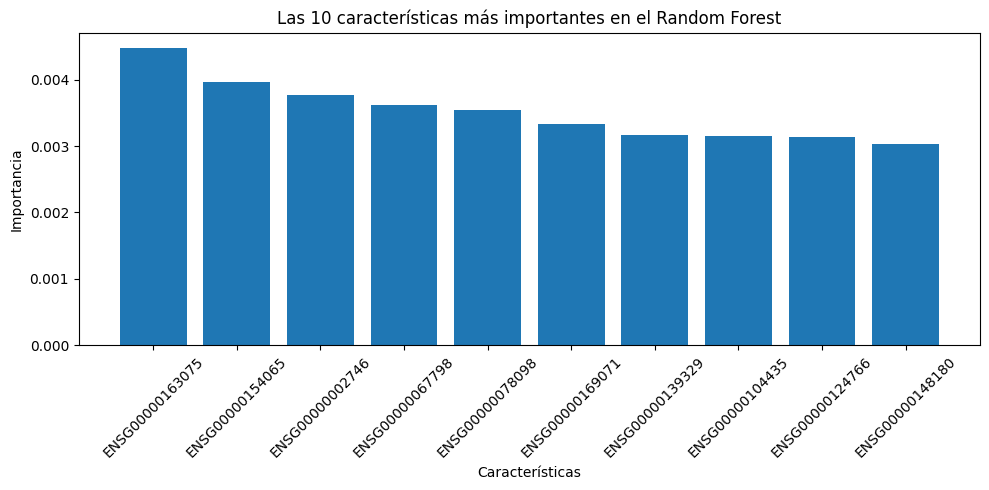

In [ ]:
# Obtener las importancias y los nombres de las características
feature_importance = rf_model.feature_importances_
feature_names = datos_limpios.columns[:-1]

# Ordenar las características por importancia en orden descendente
sorted_idx = np.argsort(feature_importance)[::-1]
sorted_feature_importance = feature_importance[sorted_idx]
sorted_feature_names = np.array(feature_names)[sorted_idx]

import matplotlib.pyplot as plt

# Crear el gráfico de barras de las 10 más importantes
plt.figure(figsize=(10, 5))
plt.bar(range(10), sorted_feature_importance[:10], align='center')
plt.xticks(range(10), sorted_feature_names[:10], rotation=45)
plt.xlabel('Características')
plt.ylabel('Importancia')
plt.title('Las 10 características más importantes en el Random Forest')
plt.tight_layout()
plt.show()

El gráfico ordena los genes según su importancia por reducción de impureza dentro del bosque. Los nombres y el orden dependen del ajuste realizado.

**¿Qué ventajas tiene la evaluación OOB? ¿En qué se diferencia de evaluar el modelo con un conjunto de test independiente?**

OOB utiliza para evaluar cada biopsia los árboles cuyo muestreo bootstrap la dejó fuera. Permite estimar el desempeño del bosque ajustado con todas las biopsias. El test independiente se reserva desde el comienzo. Más adelante se comparan el árbol y otro bosque sobre ese mismo test, con una división estratificada 70/30.


In [ ]:
# Separar los datos para la evaluación con test independiente
x_arbol = datos_sin_imputar.drop(columns='FIBROSIS')
y_arbol = datos_sin_imputar['FIBROSIS']
x_train, x_test, y_train, y_test = train_test_split(
    x_arbol, y_arbol, test_size=0.3, random_state=42, stratify=y_arbol
)
x_train, x_test = x_train.copy(), x_test.copy()
print('Entrenamiento:', x_train.shape)
print('Prueba:', x_test.shape)


Entrenamiento: (107, 64253)
Prueba: (46, 64253)


In [ ]:
# Limitar la complejidad para obtener un árbol interpretable.
# Parámetros fijados sin buscar el mejor resultado sobre el test.
clf = DecisionTreeClassifier(
    criterion='entropy', max_depth=4, min_samples_leaf=15, random_state=0
)
clf.fit(x_train, y_train)

DecisionTreeClassifier(criterion='entropy', max_depth=4, min_samples_leaf=15,
                       random_state=0)

In [ ]:
y_pred = clf.predict(x_test)
accuracy = accuracy_score(y_test, y_pred)
print(f'Exactitud del modelo: {accuracy:.2%}')
print(f'Sensibilidad para F3–F4: {recall_score(y_test, y_pred):.2%}')
print(f'Profundidad del árbol: {clf.get_depth()}')
print(f'Número de hojas: {clf.get_n_leaves()}')
print('Matriz de confusión: filas reales y columnas predichas, clases [0, 1]')
print(confusion_matrix(y_test, y_pred, labels=[0,1]))

Exactitud del modelo: 84.78%
Sensibilidad para F3–F4: 70.00%
Profundidad del árbol: 2
Número de hojas: 3
Matriz de confusión: filas reales y columnas predichas, clases [0, 1]
[[25  1]
 [ 6 14]]


Se limitó el árbol a profundidad máxima 4 y un mínimo de 15 muestras por hoja, con los mismos parámetros del modelo de referencia. La celda anterior informa la exactitud, sensibilidad, profundidad y número de hojas obtenidos para fibrosis.

In [ ]:
# Imprimir las características más importantes ordenadas
importancias_arbol = pd.Series(clf.feature_importances_, index=x_train.columns).sort_values(ascending=False)
print('Variables con importancia distinta de cero:')
print(importancias_arbol[importancias_arbol > 0].to_string())

Variables con importancia distinta de cero:
gen
ENSG00000104435    0.690375
ENSG00000163075    0.309625


Las variables con importancia distinta de cero corresponden a los genes usados en las divisiones del árbol. Su orden puede diferir del bosque, que combina muchos árboles.

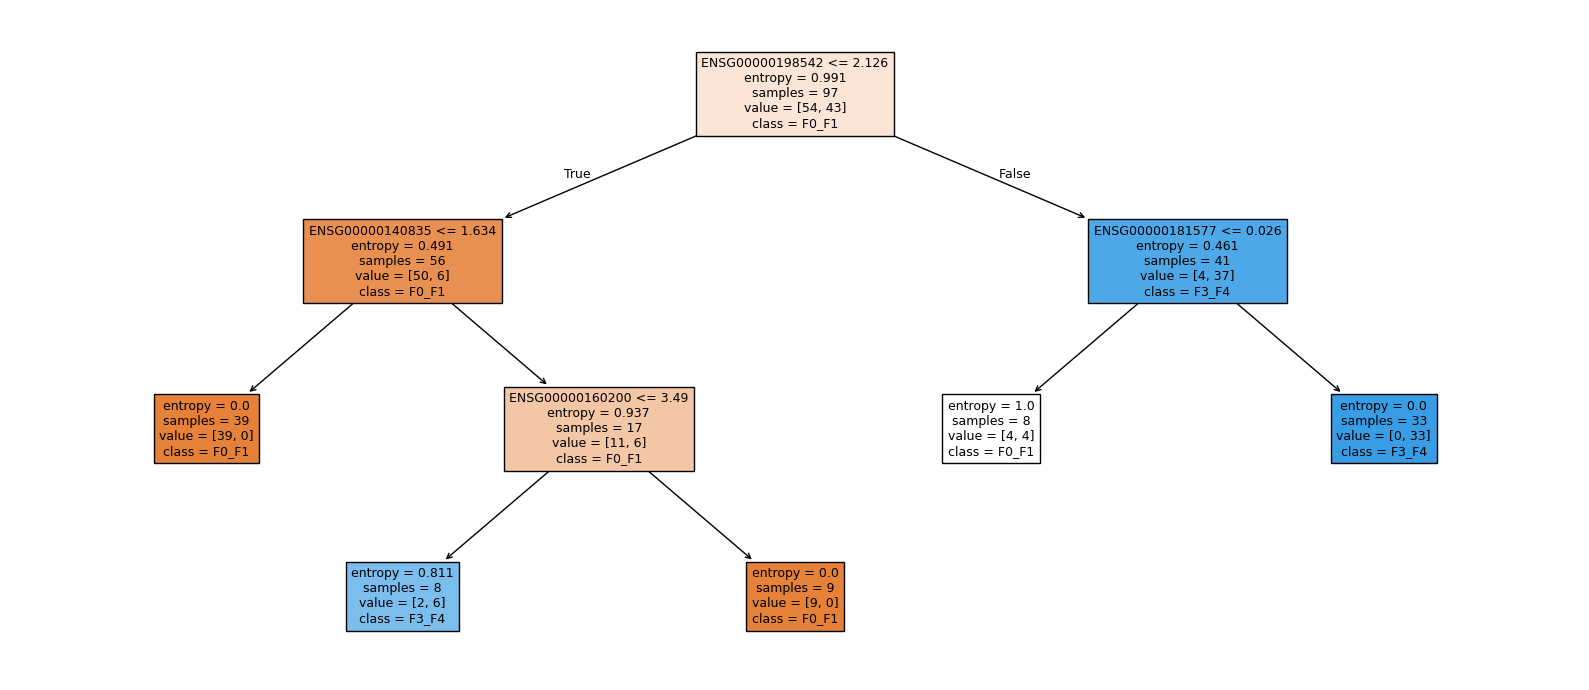

Biopsias de entrenamiento: 97
Exactitud en prueba: 77.42%
Matriz de confusión:
[[12  5]
 [ 2 12]]


In [ ]:
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.metrics import accuracy_score, confusion_matrix

# Expresión génica y etiquetas de fibrosis
x = df.drop(columns="FIBROSIS")
y = df["FIBROSIS"]

# Recuperar la división anterior
x_desarrollo, x_test, y_desarrollo, y_test = train_test_split(
    x, y,
    test_size=0.2,
    stratify=y,
    random_state=42
)

x_train, x_val, y_train, y_val = train_test_split(
    x_desarrollo, y_desarrollo,
    test_size=0.2,
    stratify=y_desarrollo,
    random_state=42
)

# Seleccionar los 500 genes usando entrenamiento
genes_modelo = x_train.var().nlargest(500).index

x_train = x_train[genes_modelo]
x_val = x_val[genes_modelo]
x_test = x_test[genes_modelo]

# Recuperar los parámetros del árbol anterior
clf = DecisionTreeClassifier(
    criterion="entropy",
    min_impurity_decrease=0.03,
    min_samples_leaf=5,
    random_state=0
)

clf.fit(x_train, y_train)

# Dibujar el árbol
plt.figure(figsize=(16, 7))

plot_tree(
    clf,
    feature_names=list(genes_modelo),
    class_names=["F0_F1", "F3_F4"],
    filled=True,
    max_depth=3,
    fontsize=9
)

plt.tight_layout()
plt.show()

# Evaluación
y_pred = clf.predict(x_test)

print("Biopsias de entrenamiento:", len(y_train))
print(f"Exactitud en prueba: {accuracy_score(y_test, y_pred):.2%}")
print("Matriz de confusión:")
print(confusion_matrix(y_test, y_pred, labels=[0, 1]))

La evaluación OOB utiliza el conjunto completo. Para comparar directamente los modelos en prueba, se entrena otro Random Forest solamente con el entrenamiento del árbol.

In [ ]:
# Comparación en el mismo conjunto de prueba; el test no se utiliza para ajustar los modelos -- consultar
rf_test = RandomForestClassifier(n_estimators=1000, random_state=0)
rf_test.fit(x_train, y_train)
pred_rf_test = rf_test.predict(x_test)
filas = []
for nombre, pred in [('Árbol de decisión', y_pred), ('Random Forest', pred_rf_test),
                     ('Siempre clase mayoritaria', np.full(len(y_test), y_train.mode().iloc[0]))]:
    filas.append({'Modelo': nombre, 'Exactitud': accuracy_score(y_test,pred),
                  'Exactitud balanceada': balanced_accuracy_score(y_test,pred),
                  'Sensibilidad clase 1': recall_score(y_test,pred),
                  'Precisión clase 1': precision_score(y_test,pred,zero_division=0),
                  'F1 clase 1': f1_score(y_test,pred)})
comparacion = pd.DataFrame(filas).set_index('Modelo')
print(comparacion.round(4).to_string())
print('Matriz de confusión del Random Forest en test:')
print(confusion_matrix(y_test,pred_rf_test,labels=[0,1]))

                           Exactitud  Exactitud balanceada  Sensibilidad clase 1  Precisión clase 1  F1 clase 1
Modelo                                                                                                         
Árbol de decisión             0.7742                0.7815                0.8571             0.7059      0.7742
Random Forest                 0.8065                0.7983                0.7143             0.8333      0.7692
Siempre clase mayoritaria     0.5484                0.5000                0.0000             0.0000      0.0000
Matriz de confusión del Random Forest en test:
[[15  2]
 [ 4 10]]


**Máquinas de vectores de soporte — SVM (Práctica 17)**

Se conservan los 500 genes y los conjuntos actuales de entrenamiento, validación y prueba. El valor de C se elige con validación. En los gráficos se mantiene el término «precisión» de la práctica, que aquí corresponde a exactitud (accuracy).


In [ ]:
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Guardar las predicciones para la comparación final
predicciones_modelos = {
    "Árbol": clf.predict(x_test),
    "Random Forest": rf_test.predict(x_test)
}

# Valores de C a evaluar, como en la práctica
valores_C = np.logspace(-5, 5, num=11)
print("Valores de C:", valores_C)


Valores de C: [1.e-05 1.e-04 1.e-03 1.e-02 1.e-01 1.e+00 1.e+01 1.e+02 1.e+03 1.e+04
 1.e+05]


**SVM con kernel radial (RBF)**


Mejor valor de C: 1.0
Precisión máxima: 0.8
Error mínimo en validación: 20.0%


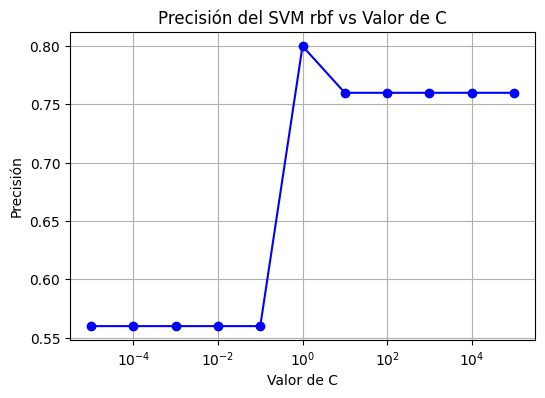


Resultados en el conjunto de prueba:
Precisión en test: 0.8064516129032258
Error en test: 19.35%

Matriz de Confusión:
[[16  1]
 [ 5  9]]

Reporte de Clasificación:
              precision    recall  f1-score   support

       F0–F1       0.76      0.94      0.84        17
       F3–F4       0.90      0.64      0.75        14

    accuracy                           0.81        31
   macro avg       0.83      0.79      0.80        31
weighted avg       0.82      0.81      0.80        31



In [ ]:
# Inicializar una lista para almacenar las precisiones
precisiones = []

# Bucle sobre los valores de C
for C in valores_C:
    # Entrenar el modelo SVM con el valor actual de C
    modelo_svm = SVC(kernel='rbf', C=C)
    modelo_svm.fit(x_train, y_train)

    # Realizar predicciones en el conjunto de validación
    predicciones = modelo_svm.predict(x_val)

    # Evaluar el rendimiento del modelo
    precision = accuracy_score(y_val, predicciones)
    precisiones.append(precision)

# Encontrar el valor de C que maximiza la precisión
mejor_C = valores_C[np.argmax(precisiones)]

# Calcular el error mínimo
error_minimo = 1 - max(precisiones)
error_porcentaje = round(error_minimo * 100, 2)

# Imprimir resultados
print(f"Mejor valor de C: {mejor_C}")
print(f"Precisión máxima: {max(precisiones)}")
print(f"Error mínimo en validación: {error_porcentaje}%")

# Gráfico de la precisión en función de C
plt.figure(figsize=(6, 4))
plt.semilogx(valores_C, precisiones, 'b-o')
plt.xlabel('Valor de C')
plt.ylabel('Precisión')
plt.title('Precisión del SVM rbf vs Valor de C')
plt.grid(True)
plt.show()

# Entrenar el modelo SVM final con el mejor valor de C
modelo_svm_final = SVC(kernel='rbf', C=mejor_C)
modelo_svm_final.fit(x_train, y_train)

# Realizar predicciones en el conjunto de prueba
predicciones_test = modelo_svm_final.predict(x_test)

# Evaluar el rendimiento del modelo en el conjunto de prueba
precision_test = accuracy_score(y_test, predicciones_test)
error_test = 1 - precision_test
error_porcentaje_test = round(error_test * 100, 2)

# Imprimir resultados en el conjunto de prueba
print("\nResultados en el conjunto de prueba:")
print(f"Precisión en test: {precision_test}")
print(f"Error en test: {error_porcentaje_test}%")

# Crear una matriz de confusión
matriz_confusion = confusion_matrix(y_test, predicciones_test, labels=[0, 1])
reporte_clasificacion = classification_report(
    y_test, predicciones_test, labels=[0, 1],
    target_names=["F0–F1", "F3–F4"], zero_division=0
)

print("\nMatriz de Confusión:")
print(matriz_confusion)
print("\nReporte de Clasificación:")
print(reporte_clasificacion)

# Conservar las predicciones para las matrices comparativas
predicciones_modelos["SVM rbf"] = predicciones_test.copy()


**SVM con kernel polinómico**


Mejor valor de C: 0.1
Precisión máxima: 0.8
Error mínimo en validación: 20.0%


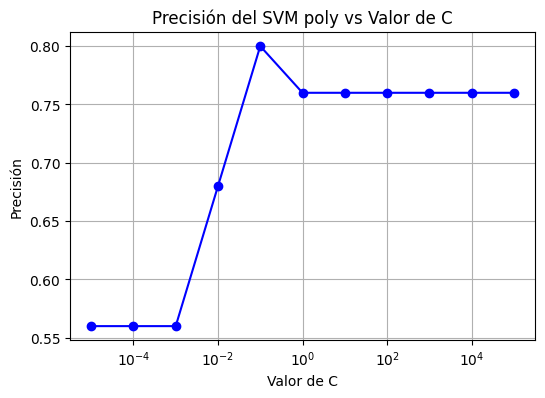


Resultados en el conjunto de prueba:
Precisión en test: 0.8387096774193549
Error en test: 16.13%

Matriz de Confusión:
[[16  1]
 [ 4 10]]

Reporte de Clasificación:
              precision    recall  f1-score   support

       F0–F1       0.80      0.94      0.86        17
       F3–F4       0.91      0.71      0.80        14

    accuracy                           0.84        31
   macro avg       0.85      0.83      0.83        31
weighted avg       0.85      0.84      0.84        31



In [ ]:
# Inicializar una lista para almacenar las precisiones
precisiones = []

# Bucle sobre los valores de C
for C in valores_C:
    # Entrenar el modelo SVM con el valor actual de C
    modelo_svm = SVC(kernel='poly', C=C)
    modelo_svm.fit(x_train, y_train)

    # Realizar predicciones en el conjunto de validación
    predicciones = modelo_svm.predict(x_val)

    # Evaluar el rendimiento del modelo
    precision = accuracy_score(y_val, predicciones)
    precisiones.append(precision)

# Encontrar el valor de C que maximiza la precisión
mejor_C = valores_C[np.argmax(precisiones)]

# Calcular el error mínimo
error_minimo = 1 - max(precisiones)
error_porcentaje = round(error_minimo * 100, 2)

# Imprimir resultados
print(f"Mejor valor de C: {mejor_C}")
print(f"Precisión máxima: {max(precisiones)}")
print(f"Error mínimo en validación: {error_porcentaje}%")

# Gráfico de la precisión en función de C
plt.figure(figsize=(6, 4))
plt.semilogx(valores_C, precisiones, 'b-o')
plt.xlabel('Valor de C')
plt.ylabel('Precisión')
plt.title('Precisión del SVM poly vs Valor de C')
plt.grid(True)
plt.show()

# Entrenar el modelo SVM final con el mejor valor de C
modelo_svm_final = SVC(kernel='poly', C=mejor_C)
modelo_svm_final.fit(x_train, y_train)

# Realizar predicciones en el conjunto de prueba
predicciones_test = modelo_svm_final.predict(x_test)

# Evaluar el rendimiento del modelo en el conjunto de prueba
precision_test = accuracy_score(y_test, predicciones_test)
error_test = 1 - precision_test
error_porcentaje_test = round(error_test * 100, 2)

# Imprimir resultados en el conjunto de prueba
print("\nResultados en el conjunto de prueba:")
print(f"Precisión en test: {precision_test}")
print(f"Error en test: {error_porcentaje_test}%")

# Crear una matriz de confusión
matriz_confusion = confusion_matrix(y_test, predicciones_test, labels=[0, 1])
reporte_clasificacion = classification_report(
    y_test, predicciones_test, labels=[0, 1],
    target_names=["F0–F1", "F3–F4"], zero_division=0
)

print("\nMatriz de Confusión:")
print(matriz_confusion)
print("\nReporte de Clasificación:")
print(reporte_clasificacion)

# Conservar las predicciones para las matrices comparativas
predicciones_modelos["SVM poly"] = predicciones_test.copy()


In [ ]:
import tensorflow as tf
from tensorflow.keras import layers, models

tf.keras.utils.set_random_seed(42)

# Arquitectura de la práctica para dos clases
model = models.Sequential()

model.add(layers.Input(shape=(x_train.shape[1],)))

model.add(layers.Dense(256, activation="relu"))
model.add(layers.BatchNormalization())
model.add(layers.Dropout(0.5))

model.add(layers.Dense(128, activation="relu"))
model.add(layers.BatchNormalization())
model.add(layers.Dropout(0.5))

model.add(layers.Dense(64, activation="relu"))
model.add(layers.BatchNormalization())

model.add(layers.Dense(2, activation="softmax"))

# Compilar el modelo
model.compile(
    optimizer="adam",
    loss=tf.keras.losses.SparseCategoricalCrossentropy(
        from_logits=False
    ),
    metrics=["accuracy"]
)

# Hiperparámetros de la práctica
epocas = 30
batch_size = 32

history = model.fit(
    x_train.to_numpy(),
    y_train.to_numpy(),
    epochs=epocas,
    batch_size=batch_size,
    validation_data=(
        x_val.to_numpy(),
        y_val.to_numpy()
    )
)

# Obtener la clase predicha para cada biopsia de prueba
probabilidades = model.predict(
    x_test.to_numpy(),
    verbose=0
)

predicciones_modelos["Red neuronal"] = np.argmax(
    probabilidades,
    axis=1
)

Epoch 1/30
4/4 ━━━━━━━━━━━━━━━━━━━━ 3s 140ms/step - accuracy: 0.6495 - loss: 0.7443 - val_accuracy: 0.5200 - val_loss: 0.8573
Epoch 2/30
4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 39ms/step - accuracy: 0.7732 - loss: 0.4890 - val_accuracy: 0.6000 - val_loss: 0.8727
Epoch 3/30
4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 49ms/step - accuracy: 0.7629 - loss: 0.4884 - val_accuracy: 0.6400 - val_loss: 0.7652
Epoch 4/30
4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 48ms/step - accuracy: 0.8660 - loss: 0.2962 - val_accuracy: 0.6400 - val_loss: 0.6302
Epoch 5/30
4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 52ms/step - accuracy: 0.8866 - loss: 0.2655 - val_accuracy: 0.7200 - val_loss: 0.4380
Epoch 6/30
4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 40ms/step - accuracy: 0.9278 - loss: 0.2369 - val_accuracy: 0.8400 - val_loss: 0.2987
Epoch 7/30
4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 37ms/step - accuracy: 0.9175 - loss: 0.1915 - val_accuracy: 0.8000 - val_loss: 0.3307
Epoch 8/30
4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 57ms/step - accuracy: 0.9072 - loss: 0.2506 - val_accuracy: 0.6800 - val_loss: 0.5475

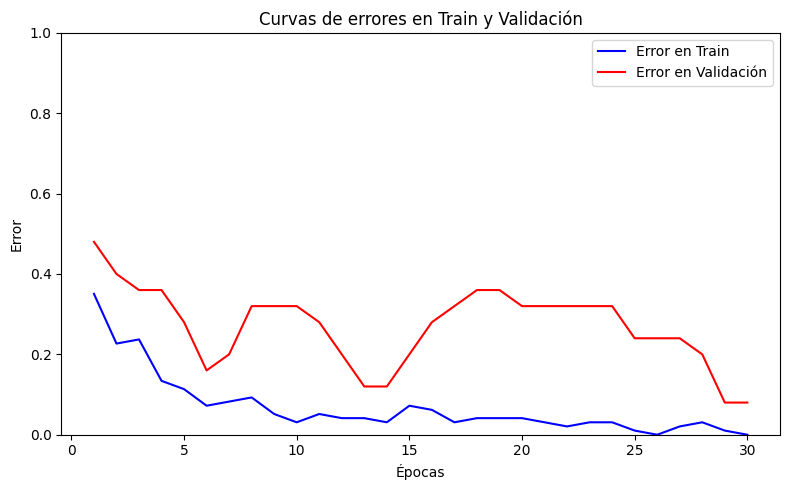

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

# Error de clasificación = 1 - exactitud
error_train = 1 - np.array(history.history["accuracy"])
error_val = 1 - np.array(history.history["val_accuracy"])

epocas_grafico = np.arange(1, len(error_train) + 1)

plt.figure(figsize=(8, 5))

plt.plot(epocas_grafico, error_train, color="blue",
         label="Error en Train")
plt.plot(epocas_grafico, error_val, color="red",
         label="Error en Validación")

plt.xlabel("Épocas")
plt.ylabel("Error")
plt.title("Curvas de errores en Train y Validación")
plt.ylim(0, 1)
plt.legend()
plt.tight_layout()
plt.show()

Las curvas muestran la evolución del error de clasificación durante las 30 épocas. El error de entrenamiento disminuye progresivamente hasta alcanzar un valor cercano a cero, mientras que el de validación presenta fluctuaciones y finaliza en un 8 %. La diferencia entre ambas curvas sugiere cierta tendencia al sobreajuste. Aunque el resultado final de validación es favorable, su variabilidad y el tamaño reducido del conjunto requieren una interpretación prudente.

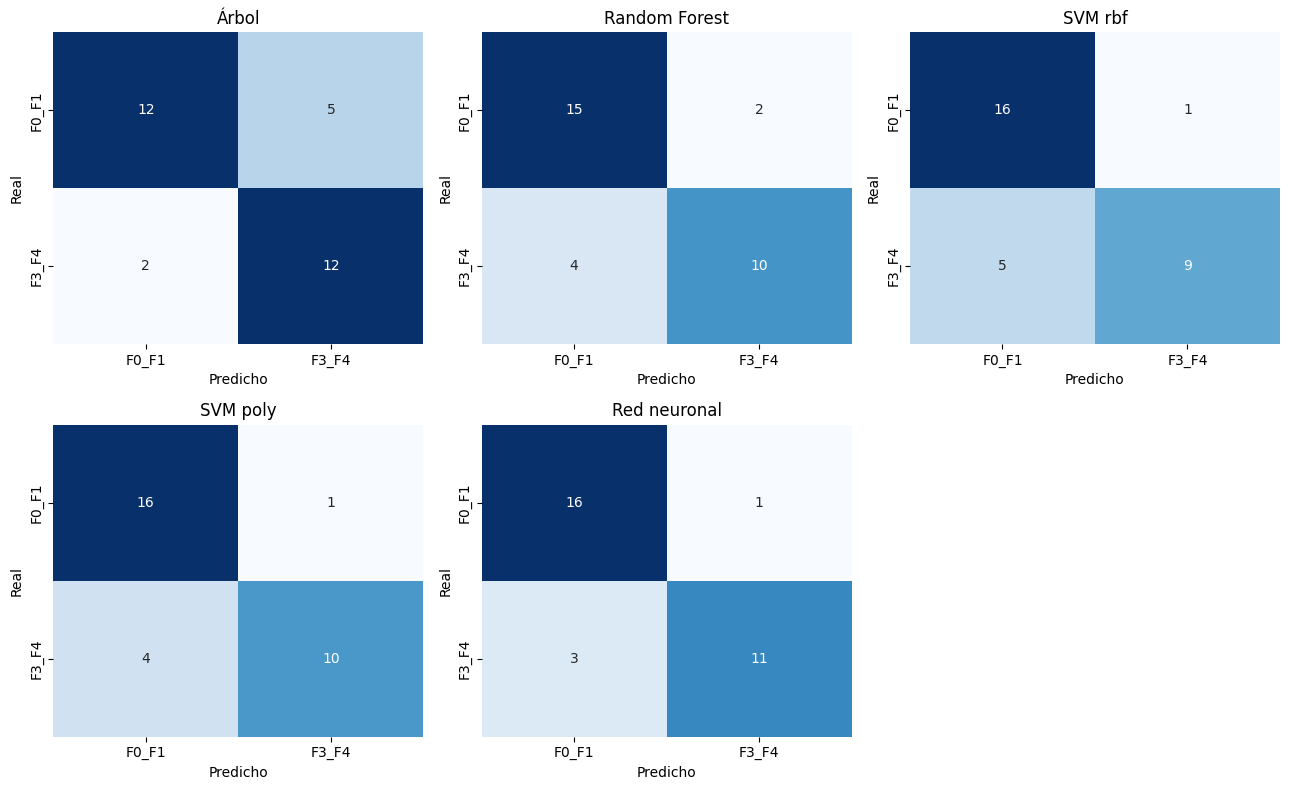

In [ ]:
fig, ejes = plt.subplots(2, 3, figsize=(13, 8))

for ax, (nombre, prediccion) in zip(
    ejes.flat,
    predicciones_modelos.items()
):
    matriz = confusion_matrix(
        y_test,
        prediccion,
        labels=[0, 1]
    )

    sns.heatmap(
        matriz,
        annot=True,
        fmt="d",
        cmap="Blues",
        cbar=False,
        xticklabels=["F0_F1", "F3_F4"],
        yticklabels=["F0_F1", "F3_F4"],
        ax=ax
    )

    ax.set_title(nombre)
    ax.set_xlabel("Predicho")
    ax.set_ylabel("Real")

# Ocultar el sexto espacio
ejes[1, 2].axis("off")

plt.tight_layout()
plt.show()

Random Forest. Combina las decisiones de 1.000 árboles para obtener una clasificación conjunta. Lo realizamos en el bloque rf_test = RandomForestClassifier(...), entrenándolo con las mismas muestras y genes del árbol. Reconoce correctamente 15 biopsias F0–F1 y 10 F3–F4, con dos errores en el primer grupo y cuatro en el segundo. Su exactitud es del 80,65 %. Esta matriz corresponde a la evaluación sobre prueba, no a la evaluación OOB del bosque anterior.

SVM con kernel RBF. Busca una separación no lineal entre los grupos a partir de sus perfiles de expresión. Lo entrenamos en el bloque de SVM mediante SVC(kernel="rbf", C=mejor_C), seleccionando C con el conjunto de validación. Clasifica correctamente 16 biopsias F0–F1 y nueve F3–F4. Confunde una biopsia del grupo inicial y cinco avanzadas, alcanzando una exactitud del 80,65 %. Reconoce bien F0–F1, pero es el que deja más casos avanzados sin detectar.

SVM con kernel polinómico. También construye una separación no lineal, utilizando una función polinómica. Lo realizamos en el mismo bloque de SVM con SVC(kernel="poly", C=mejor_C). Reconoce correctamente 16 biopsias F0–F1 y 10 F3–F4, con uno y cuatro errores, respectivamente. Su exactitud es del 83,87 %, un acierto más que el SVM RBF.

Red neuronal. Aprende combinaciones de expresión génica mediante capas de 256, 128 y 64 neuronas. La realizamos en el bloque de TensorFlow/Keras, donde construimos models.Sequential() y entrenamos con model.fit() durante 30 épocas. Reconoce correctamente 16 biopsias F0–F1 y 11 F3–F4; se equivoca en una del primer grupo y tres del segundo. Obtiene la mayor exactitud de esta prueba: 87,10 %, equivalente a 27 aciertos de 31.

## Conclusión

Se analizaron 153 biopsias hepáticas para distinguir los estadios F0–F1 y F3–F4 mediante sus perfiles de expresión génica. Los conteos se transformaron a log2(1 + CPM). Para la exploración se utilizaron todos los genes, aplicando escalado, PCA y clustering. Los agrupamientos obtenidos no mostraron una correspondencia clara con los estadios de fibrosis.

Se entrenó un Random Forest con todos los genes y las 153 biopsias, cuya exactitud OOB fue del 81,05 %. También se realizó un análisis inicial con un árbol de decisión y una división estratificada 70/30, que obtuvo una exactitud del 84,78 % sobre 46 biopsias de prueba.

Para la comparación final se utilizaron 97 biopsias de entrenamiento, 25 de validación y 31 de prueba. Se seleccionaron los 500 genes con mayor varianza utilizando únicamente el conjunto de entrenamiento. Sobre las mismas biopsias de prueba, el árbol alcanzó una exactitud del 77,42 %; Random Forest y SVM RBF, del 80,65 %; SVM polinómico, del 83,87 %; y la red neuronal, del 87,10 %.

La red neuronal obtuvo la mayor exactitud en esta evaluación, mientras que el árbol presentó la mayor sensibilidad para identificar F3–F4, con un 85,71 %. Esto muestra la importancia de comparar distintas métricas y considerar los tipos de errores de cada modelo. Los resultados OOB y los del árbol inicial corresponden a evaluaciones diferentes y deben interpretarse por separado.

Los resultados sugieren que la expresión génica contiene información útil para diferenciar ambos grupos. Sin embargo, el tamaño reducido del conjunto de prueba y el uso de una sola cohorte requieren validar el desempeño con evaluaciones adicionales y muestras independientes antes de considerar una aplicación diagnóstica.